# 02 — Exploratory Data Analysis and Text Analysis

## Objective

To explore the structure, distribution, linguistic characteristics, and thematic
patterns of the cleaned biomedical literature corpus before applying NLP and
machine learning techniques.

The analysis examines publication characteristics, corpus composition,
abstract-length distributions, layer-wise differences, and frequently occurring
terms to establish an evidence-based understanding of the dataset.

In [1]:
# ============================================================
# STEP 1 — LOAD FINAL DATASET
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

FINAL_FILE = "pubmed_medical_affairs_3layer_corpus_FINAL.csv"

df = pd.read_csv(FINAL_FILE)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (21256, 6)

Columns:
['pmid', 'title', 'abstract', 'year', 'journal', 'layer']


,pmid,title,abstract,year,journal,layer
0,41483736,Intracranial activity of antibody-drug conjuga...,Antibody-drug conjugates (ADCs) represent a ra...,2025.0,Cancer treatment reviews,L1_scientific_engagement
1,41483728,Effect of quetiapine versus haloperidol on del...,INTRODUCTION: Delirium is a neuropsychiatric c...,2025.0,Asian journal of psychiatry,L1_scientific_engagement
2,41483727,Vision-language models in diagnostic imaging: ...,BACKGROUND: Radiology faces an unprecedented w...,2025.0,International journal of medical informatics,L1_scientific_engagement
3,41483666,The complexity of dystrophin transcription and...,Duchenne muscular dystrophy (DMD) is a rare ge...,2025.0,Neuromuscular disorders : NMD,L1_scientific_engagement
4,41483580,EEG biomarkers for a precision-medicine approa...,Major depressive disorder (MDD) is a prevalent...,2025.0,Psychiatry research. Neuroimaging,L1_scientific_engagement


In [2]:
# ============================================================
# STEP 2 — BASIC DATASET OVERVIEW
# ============================================================

print("Number of records:", len(df))
print("Number of columns:", len(df.columns))

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate PMIDs:", df["pmid"].duplicated().sum())

Number of records: 21256
Number of columns: 6

Data types:
pmid          int64
title        object
abstract     object
year        float64
journal      object
layer        object
dtype: object

Missing values:
pmid         0
title       42
abstract     0
year         8
journal      0
layer        0
dtype: int64

Duplicate rows: 0
Duplicate PMIDs: 0


In [3]:
# ============================================================
# STEP 3 — LAYER DISTRIBUTION
# ============================================================

layer_counts = df["layer"].value_counts()

layer_percent = (
    df["layer"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

layer_summary = pd.DataFrame({
    "Count": layer_counts,
    "Percentage": layer_percent
})

display(layer_summary)

,Count,Percentage
layer,,
L1_scientific_engagement,9599,45.16
L3_comparative_critical,5849,27.52
L2_safety_risk,5808,27.32


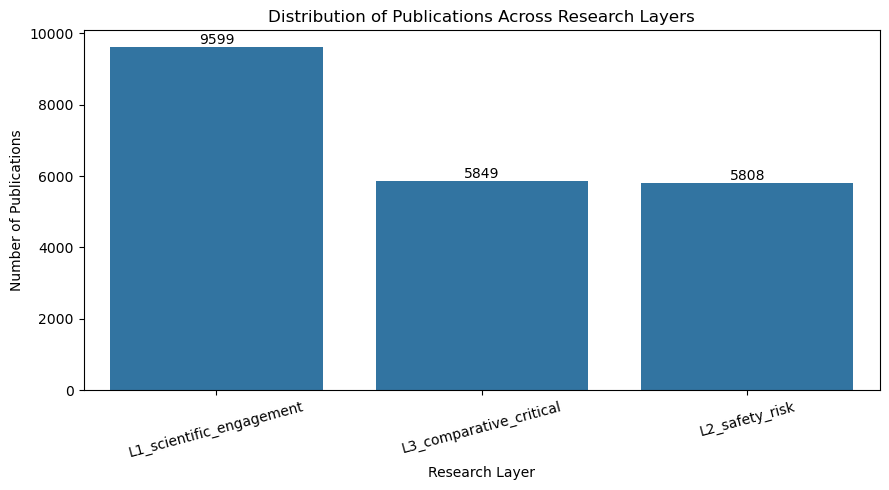

In [4]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=layer_summary.index,
    y=layer_summary["Count"]
)

plt.title("Distribution of Publications Across Research Layers")
plt.xlabel("Research Layer")
plt.ylabel("Number of Publications")
plt.xticks(rotation=15)

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [5]:
# ============================================================
# STEP 4 — PUBLICATION YEAR DISTRIBUTION
# ============================================================

year_counts = (
    df["year"]
    .value_counts(dropna=False)
    .sort_index()
)

display(year_counts)

year
2024.0       14
2025.0    21234
NaN           8
Name: count, dtype: int64

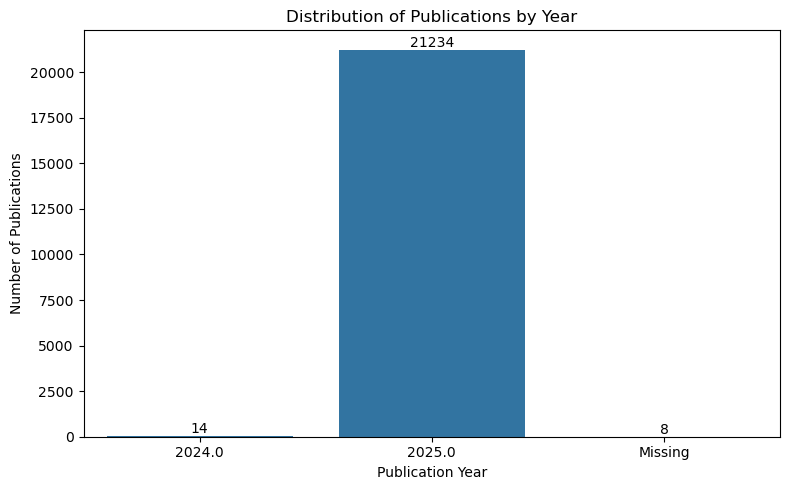

In [6]:
plt.figure(figsize=(8, 5))

year_plot = (
    df["year"]
    .fillna("Missing")
    .astype(str)
    .value_counts()
    .sort_index()
)

ax = sns.barplot(
    x=year_plot.index,
    y=year_plot.values
)

plt.title("Distribution of Publications by Year")
plt.xlabel("Publication Year")
plt.ylabel("Number of Publications")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [7]:
# ============================================================
# STEP 5 — ABSTRACT LENGTH
# ============================================================

df["abstract_char_count"] = df["abstract"].str.len()

df["abstract_word_count"] = (
    df["abstract"]
    .str.split()
    .str.len()
)

display(
    df[
        ["abstract_char_count", "abstract_word_count"]
    ].describe()
)

,abstract_char_count,abstract_word_count
count,21256.000000,21256.000000
mean,1723.961423,230.931878
std,589.575058,85.380536
min,127.000000,1.000000
25%,1370.000000,179.000000
50%,1680.000000,223.000000
75%,1983.000000,265.000000
max,14210.000000,2178.000000


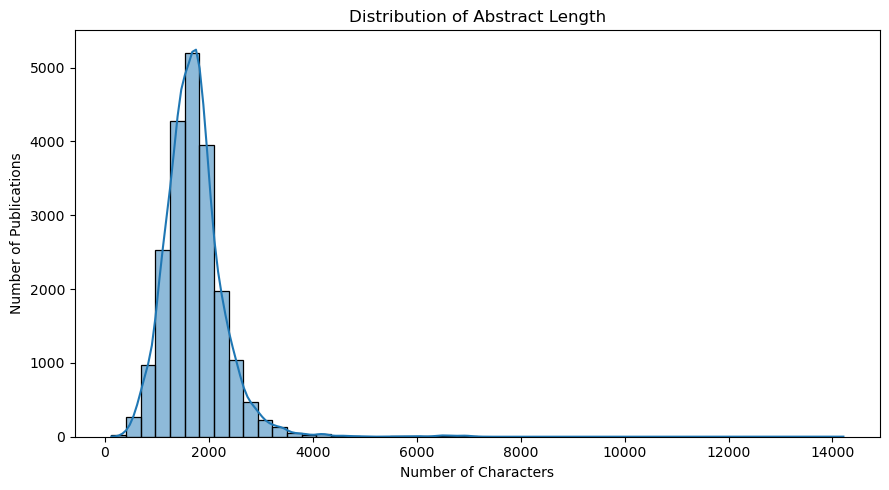

In [8]:
plt.figure(figsize=(9, 5))

sns.histplot(
    df["abstract_char_count"],
    bins=50,
    kde=True
)

plt.title("Distribution of Abstract Length")
plt.xlabel("Number of Characters")
plt.ylabel("Number of Publications")

plt.tight_layout()
plt.show()

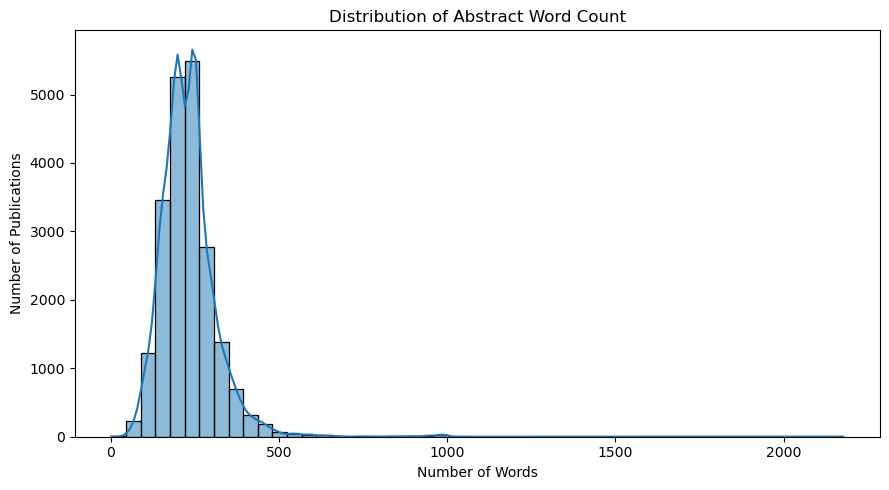

In [10]:
plt.figure(figsize=(9, 5))

sns.histplot(
    df["abstract_word_count"],
    bins=50,
    kde=True
)

plt.title("Distribution of Abstract Word Count")
plt.xlabel("Number of Words")
plt.ylabel("Number of Publications")

plt.tight_layout()
plt.show()

In [11]:
# ============================================================
# STEP 7 — EXTREME ABSTRACT LENGTHS
# ============================================================

print("Shortest abstracts:")
display(
    df[
        ["pmid", "title", "abstract_word_count", "layer"]
    ]
    .sort_values("abstract_word_count")
    .head(10)
)

print("\nLongest abstracts:")
display(
    df[
        ["pmid", "title", "abstract_word_count", "layer"]
    ]
    .sort_values("abstract_word_count", ascending=False)
    .head(10)
)

Shortest abstracts:


,pmid,title,abstract_word_count,layer
16216,41436046,[The applications and challenges of rapid dete...,1,L3_comparative_critical
17243,41372067,[Robots and embodied intelligence in endoscopi...,3,L3_comparative_critical
13341,41079276,Endoscopic strategies for the management of lo...,40,L2_safety_risk
15647,41468091,Adjuvant Chemoradiotherapy Versus Radiotherapy...,42,L3_comparative_critical
9004,41101910,Orthobiologics for Meniscus Injuries.,43,L1_scientific_engagement
20607,41203306,Retirement Considerations for Obstetrician-Gyn...,46,L3_comparative_critical
15648,41468071,Induction of Labour Versus Standard Care to Pr...,47,L3_comparative_critical
14300,41033877,Daily standup meeting: enhancing accountabilit...,49,L2_safety_risk
8778,41109726,Advantages and Disadvantages of the Arthroscop...,49,L1_scientific_engagement
1886,41389712,TL1A blockade in inflammatory bowel diseases: ...,49,L1_scientific_engagement



Longest abstracts:


,pmid,title,abstract_word_count,layer
7707,41152983,Screening for the prevention and early detecti...,2178,L1_scientific_engagement
11230,41288132,Interventions for quitting vaping.,1033,L2_safety_risk
10960,41312789,Human stem cells for decompensated cirrhosis i...,997,L2_safety_risk
12486,41161684,Liraglutide for adults living with obesity.,997,L2_safety_risk
11476,41263273,Topical immunosuppressants for blepharitis in ...,997,L2_safety_risk
11907,41216939,Indications and timings for caffeine initiatio...,996,L2_safety_risk
11015,41307301,Interventions for treating urinary incontinenc...,996,L2_safety_risk
10223,41400094,Multimodal health behaviour-changing intervent...,995,L2_safety_risk
10511,41363159,Manual therapy with exercise for neck pain.,995,L2_safety_risk
14640,41017778,Antibiotic prophylaxis for corneal abrasion.,993,L2_safety_risk


In [14]:
# ============================================================
# STEP 8 — ABSTRACT LENGTH BY LAYER
# ============================================================

layer_length_summary = (
    df.groupby("layer")["abstract_word_count"]
      .agg([
          "count",
          "mean",
          "median",
          "std",
          "min",
          "max"
      ])
      .round(2)
)

display(layer_length_summary)

,count,mean,median,std,min,max
layer,,,,,,
L1_scientific_engagement,9599,232.81,227.0,79.64,43,2178
L2_safety_risk,5808,239.23,229.0,99.59,40,1033
L3_comparative_critical,5849,219.60,210.0,77.69,1,991


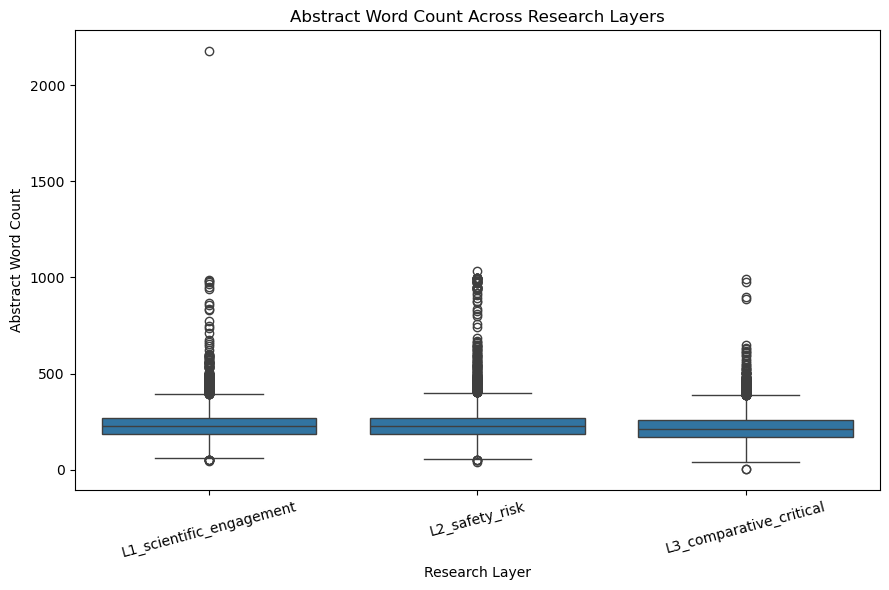

In [15]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="layer",
    y="abstract_word_count"
)

plt.title("Abstract Word Count Across Research Layers")
plt.xlabel("Research Layer")
plt.ylabel("Abstract Word Count")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [16]:
# ============================================================
# STEP 9 — TOP JOURNALS
# ============================================================

top_journals = (
    df["journal"]
    .value_counts()
    .head(20)
)

display(top_journals)

journal
Cureus                                                523
Frontiers in immunology                               344
International journal of molecular sciences           342
Medicine                                              306
Frontiers in pharmacology                             229
Frontiers in medicine                                 166
Scientific reports                                    159
Cancers                                               154
Journal of clinical medicine                          139
Frontiers in oncology                                 120
Biomedicines                                          109
Drug design, development and therapy                   94
Frontiers in neurology                                 88
PloS one                                               87
Cells                                                  87
Frontiers in endocrinology                             84
International journal of biological macromolecules     84
Pharma

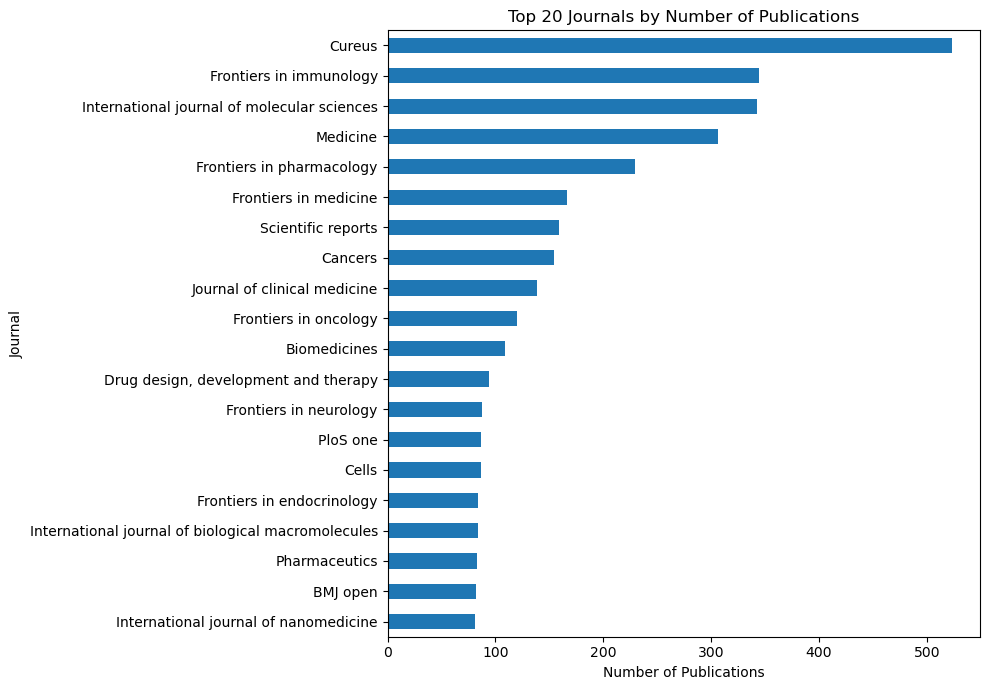

In [17]:
plt.figure(figsize=(10, 7))

top_journals.sort_values().plot(
    kind="barh"
)

plt.title("Top 20 Journals by Number of Publications")
plt.xlabel("Number of Publications")
plt.ylabel("Journal")

plt.tight_layout()
plt.show()

In [18]:
# ============================================================
# STEP 10 — SAVE EDA DATA
# ============================================================

EDA_FILE = "pubmed_medical_affairs_3layer_corpus_EDA.csv"

df.to_csv(
    EDA_FILE,
    index=False
)

print("EDA dataset saved as:", EDA_FILE)

EDA dataset saved as: pubmed_medical_affairs_3layer_corpus_EDA.csv


In [1]:
# ============================================================
# STEP 11 — FINAL DATASET VALIDATION
# ============================================================

import pandas as pd
from pathlib import Path

FINAL_FILE = "pubmed_medical_affairs_3layer_corpus_FINAL.csv"

# Confirm that the expected dataset exists
if not Path(FINAL_FILE).exists():
    raise FileNotFoundError(
        f"{FINAL_FILE} was not found in the current working directory. "
        "Check the file location before proceeding."
    )

# Load the dataset used for subsequent NLP analysis
df = pd.read_csv(FINAL_FILE)

print("=" * 60)
print("FINAL DATASET AUDIT")
print("=" * 60)

print("\n1. Dataset shape")
print(df.shape)

print("\n2. Column names")
print(df.columns.tolist())

print("\n3. Missing values")
print(df.isnull().sum())

print("\n4. Duplicate records")
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate PMIDs:", df["pmid"].duplicated().sum())

print("\n5. Publication-year distribution")
print(
    df["year"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\n6. Layer distribution")
print(
    df["layer"]
    .value_counts(dropna=False)
)

print("\n7. Abstract quality")
abstracts = df["abstract"].fillna("").astype(str).str.strip()

print("Empty abstracts:", abstracts.eq("").sum())
print("Abstracts under 50 characters:", abstracts.str.len().lt(50).sum())
print("Abstracts under 200 characters:", abstracts.str.len().lt(200).sum())

print("\n8. Abstract length by layer")
df["abstract_word_count"] = abstracts.str.split().str.len()

print(
    df.groupby("layer")["abstract_word_count"]
      .agg(["count", "mean", "median", "min", "max"])
      .round(2)
)

print("\n9. Shortest abstracts")
display(
    df.assign(
        abstract_length=abstracts.str.len()
    )
    .sort_values("abstract_length")
    [["pmid", "title", "year", "layer", "abstract_length", "abstract"]]
    .head(10)
)

print("\n10. Final validation complete.")

FINAL DATASET AUDIT

1. Dataset shape
(21256, 6)

2. Column names
['pmid', 'title', 'abstract', 'year', 'journal', 'layer']

3. Missing values
pmid         0
title       42
abstract     0
year         8
journal      0
layer        0
dtype: int64

4. Duplicate records
Duplicate rows: 0
Duplicate PMIDs: 0

5. Publication-year distribution
year
2024.0       14
2025.0    21234
NaN           8
Name: count, dtype: int64

6. Layer distribution
layer
L1_scientific_engagement    9599
L3_comparative_critical     5849
L2_safety_risk              5808
Name: count, dtype: int64

7. Abstract quality
Empty abstracts: 0
Abstracts under 50 characters: 0
Abstracts under 200 characters: 1

8. Abstract length by layer
                          count    mean  median  min   max
layer                                                     
L1_scientific_engagement   9599  232.81   227.0   43  2178
L2_safety_risk             5808  239.23   229.0   40  1033
L3_comparative_critical    5849  219.60   210.0    1   9

,pmid,title,year,layer,abstract_length,abstract
16216,41436046,[The applications and challenges of rapid dete...,2025.0,L3_comparative_critical,127,法医毒物学作为法医学的重要分支，是连接中毒事件调查、司法公正裁决与公共安全保障的关键技术支撑...
15647,41468091,Adjuvant Chemoradiotherapy Versus Radiotherapy...,2025.0,L3_comparative_critical,313,(Abstracted from Lancet Oncol 2025;26(10):1370...
9004,41101910,Orthobiologics for Meniscus Injuries.,2025.0,L1_scientific_engagement,315,The biologic enhancement of meniscal tears aim...
13341,41079276,Endoscopic strategies for the management of lo...,2025.0,L2_safety_risk,317,Endoscopic resection is the standard approach ...
6943,41180001,Efficacy and Safety of Bictegravir Plus Lenaca...,2025.0,L1_scientific_engagement,322,ARTISTRY-1 is a phase 2/3 trial of bictegravir...
1811,41392927,R WE ready for reimbursement? A round-up of de...,2025.0,L1_scientific_engagement,336,"In this update, we explore a review on transpo..."
8778,41109726,Advantages and Disadvantages of the Arthroscop...,2025.0,L1_scientific_engagement,349,Arthroscopic ankle fusion has become the prefe...
15182,40991743,Attaching the Sacrocolpopexy Mesh to the Sacrum.,2025.0,L2_safety_risk,359,Attachment of the mesh to the sacral anterior ...
1886,41389712,TL1A blockade in inflammatory bowel diseases: ...,2025.0,L1_scientific_engagement,362,TL1A inhibitors offer a novel therapeutic stra...
5566,41233099,Updates on Multimodal Analgesia for Orthopedic...,2025.0,L1_scientific_engagement,369,Multimodal analgesia has emerged as the standa...



10. Final validation complete.


In [2]:
# ============================================================
# STEP 12A — INVESTIGATE UNUSUALLY SHORT ABSTRACTS
# ============================================================

import pandas as pd

# Work on a copy; do not modify the original dataset
df = df.copy()

# Ensure abstracts are represented consistently as strings
df["abstract"] = df["abstract"].fillna("").astype(str).str.strip()

# Calculate word and character counts
df["abstract_word_count"] = df["abstract"].str.split().str.len()
df["abstract_char_count"] = df["abstract"].str.len()

print("Dataset shape:", df.shape)

print("\nAbstracts with fewer than 10 words:")

short_abstracts = (
    df.loc[
        df["abstract_word_count"] < 10,
        [
            "pmid",
            "title",
            "year",
            "journal",
            "layer",
            "abstract_word_count",
            "abstract_char_count",
            "abstract",
        ],
    ]
    .sort_values("abstract_word_count")
)

display(short_abstracts)

print("\nNumber of abstracts with fewer than 10 words:",
      len(short_abstracts))

print("\nAbstracts with fewer than 50 characters:",
      df["abstract_char_count"].lt(50).sum())

print("\nAbstracts with fewer than 200 characters:",
      df["abstract_char_count"].lt(200).sum())

Dataset shape: (21256, 8)

Abstracts with fewer than 10 words:


,pmid,title,year,journal,layer,abstract_word_count,abstract_char_count,abstract
16216,41436046,[The applications and challenges of rapid dete...,2025.0,Fa yi xue za zhi,L3_comparative_critical,1,127,法医毒物学作为法医学的重要分支，是连接中毒事件调查、司法公正裁决与公共安全保障的关键技术支撑...
17243,41372067,[Robots and embodied intelligence in endoscopi...,2025.0,Zhonghua er bi yan hou tou jing wai ke za zhi ...,L3_comparative_critical,3,374,经鼻内镜手术（endoscopic transnasal surgery，ETS）是治疗鼻窦...



Number of abstracts with fewer than 10 words: 2

Abstracts with fewer than 50 characters: 0

Abstracts with fewer than 200 characters: 1


In [3]:
# ============================================================
# STEP 12B — BASIC TEXT PREPROCESSING
# ============================================================

import re
import html

# Preserve the source text
df["abstract_original"] = df["abstract"].copy()

def clean_abstract(text):
    """
    Perform conservative cleaning while retaining the meaning
    and terminology of the biomedical abstract.
    """

    # Decode HTML entities, if present
    text = html.unescape(str(text))

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Standardise case
    text = text.lower()

    # Replace repeated whitespace with a single space
    text = re.sub(r"\s+", " ", text)

    # Remove leading and trailing whitespace
    text = text.strip()

    return text

# Create a separate column for cleaned text
df["abstract_clean"] = df["abstract_original"].apply(clean_abstract)

# Compare original and cleaned text
print("Original abstract:")
print(df["abstract_original"].iloc[0])

print("\nCleaned abstract:")
print(df["abstract_clean"].iloc[0])

print("\nOriginal columns preserved:", "abstract_original" in df.columns)
print("Cleaned-text column created:", "abstract_clean" in df.columns)
print("Missing cleaned abstracts:", df["abstract_clean"].isna().sum())

Original abstract:
Antibody-drug conjugates (ADCs) represent a rapidly evolving class of therapeutics in non-small cell lung cancer (NSCLC), offering targeted delivery of cytotoxic payloads to tumor cells while minimizing off-target toxicity. Although ADCs have demonstrated promising results in NSCLC, their efficacy in treating central nervous system (CNS) metastases has been uncertain due to concerns over blood-brain barrier (BBB) penetration and the lack of dedicated CNS-specific evaluations in clinical trials. However, emerging evidence challenges this paradigm. While earlier-generation ADCs such as T-DM1 exhibited limited CNS efficacy, newer ADCs employing optimized linkers and cytotoxins demonstrate more favorable efficacy and toxicity profiles. Selected agents, including trastuzumab deruxtecan, datopotamab deruxtecan and patritumab deruxtecan, have all shown intracranial responses in patients with advanced NSCLC with brain metastases (BM). Proposed mechanisms facilitating CNS act